In [3]:
!pip install rdkit
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
import re
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import rdFingerprintGenerator, DataStructs
from scipy.stats import spearmanr

In [4]:
# ============================================================
# Day 4 Cell 1 : 直接从 Day 3 加载预测，不重训
# ============================================================

with open('OOD_results.pkl', 'rb') as f:
    results = pickle.load(f)

SPLIT_NAMES = ['random', 'leave_cell', 'scaffold']
preds_store = {}

for split in SPLIT_NAMES:
    test_df = pd.read_pickle(f'test_{split}.pkl').reset_index(drop=True)
    preds_store[split] = {
        'test_df':  test_df,
        'preds':    results[split]['test_preds'],
        'trues':    results[split]['test_trues'],
        'spearman': results[split]['test_spearman'],
        'rmse':     results[split]['test_rmse'],
    }
    print(f"[{split:11s}] Spearman={results[split]['test_spearman']:.4f} | "
          f"RMSE={results[split]['test_rmse']:.4f}")

with open('OOD_preds.pkl', 'wb') as f:
    pickle.dump(preds_store, f)
print("\n✅ OOD_preds.pkl 已保存")

[random     ] Spearman=0.8643 | RMSE=1.0758
[leave_cell ] Spearman=0.8462 | RMSE=1.0876
[scaffold   ] Spearman=0.2920 | RMSE=2.1825

✅ OOD_preds.pkl 已保存


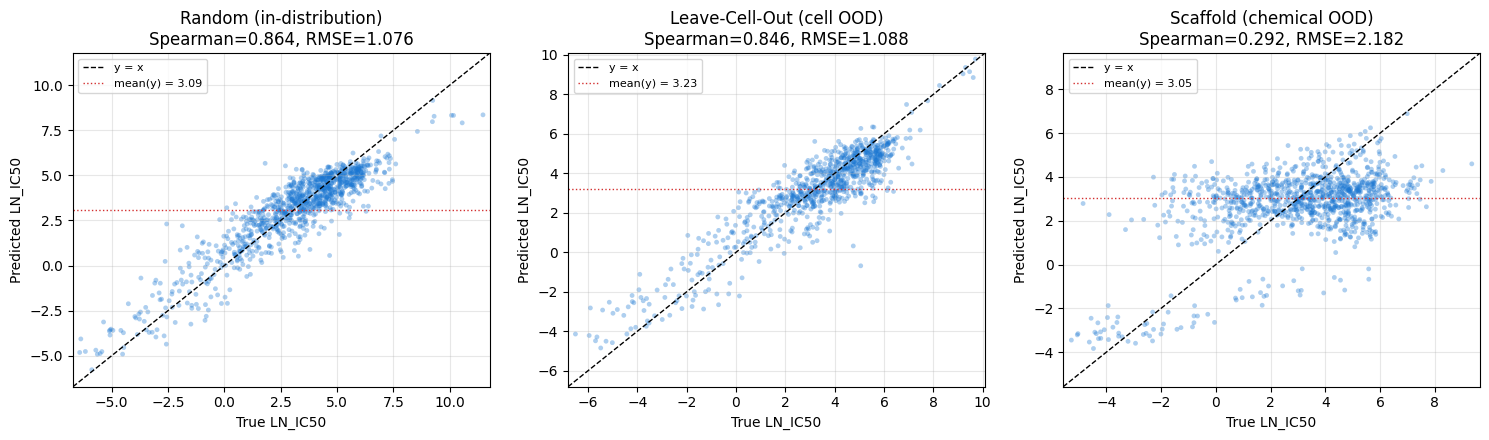

✅ OOD_scatter_three_splits.png


In [5]:
# ============================================================
# Cell 2: 三 split 散点图
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
titles = ['Random (in-distribution)', 'Leave-Cell-Out (cell OOD)', 'Scaffold (chemical OOD)']

for ax, split, title in zip(axes, SPLIT_NAMES, titles):
    p = preds_store[split]
    preds, trues = p['preds'], p['trues']

    ax.scatter(trues, preds, alpha=0.35, s=12, color='#1976d2', edgecolor='none')

    lims = [min(trues.min(), preds.min()) - 0.3,
            max(trues.max(), preds.max()) + 0.3]
    ax.plot(lims, lims, 'k--', linewidth=1, label='y = x')

    # 均值参考线
    ax.axhline(trues.mean(), color='#d32f2f', linestyle=':', linewidth=1,
               label=f'mean(y) = {trues.mean():.2f}')

    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel('True LN_IC50')
    ax.set_ylabel('Predicted LN_IC50')
    ax.set_title(f"{title}\nSpearman={p['spearman']:.3f}, RMSE={p['rmse']:.3f}")
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('OOD_scatter_three_splits.png', dpi=150)
plt.show()
print("✅ OOD_scatter_three_splits.png")

In [6]:
# ============================================================
# Cell 3: Top-K 误差最大的 (drug, cell) 对
# ============================================================

def top_k_errors(split, k=10):
    p = preds_store[split]
    df = p['test_df'].copy()
    df['pred'] = p['preds']
    df['true'] = p['trues']
    df['abs_err'] = (df['pred'] - df['true']).abs()
    top = df.nlargest(k, 'abs_err')[
        ['DRUG_NAME', 'ModelID', 'true', 'pred', 'abs_err']].reset_index(drop=True)
    return top

for split in SPLIT_NAMES:
    print(f"\n{'='*80}\n[{split}] Top-10 误差最大")
    print(top_k_errors(split, k=10).to_string(index=False))


[random] Top-10 误差最大
        DRUG_NAME    ModelID      true      pred  abs_err
           743380 ACH-000631 -2.555500  2.307165 4.862665
           LMP744 ACH-000464  4.670968  0.559451 4.111517
           743380 ACH-000558 -1.862143  2.205390 4.067533
       Dabrafenib ACH-000863  1.811461  5.668854 3.857393
              JQ1 ACH-000269  5.102088  1.724496 3.377592
           630600 ACH-000863  6.288145  3.007313 3.280833
N-acetyl cysteine ACH-000464 11.474212  8.354691 3.119521
          AZD4547 ACH-000622  6.388976  3.292289 3.096688
          OSI-027 ACH-000098  0.110165  3.203295 3.093130
      Gemcitabine ACH-000137 -3.697049 -0.691149 3.005900

[leave_cell] Top-10 误差最大
        DRUG_NAME    ModelID      true      pred  abs_err
      Gemcitabine ACH-000595  5.058181 -0.683758 5.741939
           LMP744 ACH-000595  4.755858  0.321367 4.434491
          AZD4547 ACH-000622  6.388976  3.086102 3.302874
        Docetaxel ACH-000469 -5.905902 -2.819826 3.086076
       Irinotecan ACH-00

In [7]:
# ============================================================
# Cell 4 : 按药物聚合误差 + Spearman 分布
# ============================================================
def per_drug_stats(split, min_n=3):
    p = preds_store[split]
    df = p['test_df'].copy()
    df['pred'] = p['preds']
    df['true'] = p['trues']
    df['err'] = df['pred'] - df['true']

    rows = []
    for drug, g in df.groupby('DRUG_NAME'):
        if len(g) < min_n:
            continue
        # 只有 true 有方差时 Spearman 才有意义
        if g['true'].std() < 1e-6:
            continue
        sp = spearmanr(g['pred'], g['true']).correlation
        rows.append({
            'DRUG_NAME': drug,
            'n': len(g),
            'rmse': float(np.sqrt(np.mean(g['err']**2))),
            'mean_err': float(g['err'].mean()),
            'spearman': float(sp) if not np.isnan(sp) else np.nan,
            'true_std': float(g['true'].std()),
        })

    if len(rows) == 0:
        return pd.DataFrame(columns=[
            'DRUG_NAME', 'n', 'rmse', 'mean_err', 'spearman', 'true_std'])

    return pd.DataFrame(rows).sort_values('rmse', ascending=False)


for split in SPLIT_NAMES:
    pstats = per_drug_stats(split, min_n=3)
    print(f"\n{'='*80}\n[{split}] 有效药物数={len(pstats)}")
    if len(pstats) == 0:
        print("  ⚠️ 没有药物达到 min_n=3，检查 test 集大小")
        continue
    print("  RMSE 最大的 Top-5 药物:")
    print(pstats.head(5).to_string(index=False))
    print("  RMSE 最小的 Top-5 药物:")
    print(pstats.tail(5).to_string(index=False))
    print(f"  Median RMSE = {pstats['rmse'].median():.3f}")
    print(f"  Median per-drug Spearman = {pstats['spearman'].median():.3f}")


[random] 有效药物数=189
  RMSE 最大的 Top-5 药物:
        DRUG_NAME  n     rmse  mean_err  spearman  true_std
           743380  7 2.504429  1.527369  0.571429  2.280824
N-acetyl cysteine  5 2.133264 -1.978653  0.400000  0.931592
       Teniposide  3 2.105246 -1.233042  0.500000  2.430036
           630600  4 2.088440 -1.041263  0.800000  2.511891
           LMP744  7 2.070933  0.072215  0.714286  2.452788
  RMSE 最小的 Top-5 药物:
  DRUG_NAME  n     rmse  mean_err  spearman  true_std
      MN-64  3 0.333156 -0.163656      -0.5  0.288815
 Serdemetan  4 0.280242 -0.061134       0.8  0.387994
Leflunomide  4 0.247310 -0.127843       0.8  0.602453
     AZ6102  3 0.235847 -0.206862       0.5  0.121209
    GNE-317  5 0.128322  0.017451       0.9  0.231399
  Median RMSE = 0.893
  Median per-drug Spearman = 0.500

[leave_cell] 有效药物数=227
  RMSE 最大的 Top-5 药物:
        DRUG_NAME  n     rmse  mean_err  spearman  true_std
      Gemcitabine  4 2.969606 -1.582142       0.8  3.000767
           LMP744  3 2.593263 -1

In [8]:
# ============================================================
# Cell 4b: 高误差药物中是否有 TMZ / 靶向药
# ============================================================
# 常见 GBM 相关药物关键词
GBM_KEYWORDS = ['Temozolomide', 'TMZ', 'Lomustine', 'Carmustine',
                'EGFR', 'Erlotinib', 'Gefitinib', 'Lapatinib',
                'BRAF', 'Vemurafenib', 'Dabrafenib',
                'MTOR', 'Everolimus', 'Temsirolimus',
                'PI3K', 'Buparlisib']

for split in SPLIT_NAMES:
    pstats = per_drug_stats(split, min_n=10)
    top20 = pstats.head(20)['DRUG_NAME'].tolist()
    hit = [d for d in top20 if any(k.lower() in d.lower() for k in GBM_KEYWORDS)]
    print(f"[{split:11s}] Top-20 高误差药物中 GBM 相关: {hit if hit else '无'}")

[random     ] Top-20 高误差药物中 GBM 相关: 无
[leave_cell ] Top-20 高误差药物中 GBM 相关: 无
[scaffold   ] Top-20 高误差药物中 GBM 相关: ['Temozolomide', 'Buparlisib']


In [9]:
# ============================================================
# Cell 5: 按细胞系聚合误差 + Spearman 分布
# ============================================================
def per_cell_stats(split, min_n=20):
    p = preds_store[split]
    df = p['test_df'].copy()
    df['pred'] = p['preds']
    df['true'] = p['trues']
    df['err'] = df['pred'] - df['true']

    rows = []
    for cell, g in df.groupby('ModelID'):
        if len(g) < min_n:
            continue
        sp = spearmanr(g['pred'], g['true']).correlation
        rows.append({
            'ModelID': cell,
            'n': len(g),
            'rmse': float(np.sqrt(np.mean(g['err']**2))),
            'mean_err': float(g['err'].mean()),
            'spearman': float(sp) if not np.isnan(sp) else np.nan,
        })
    return pd.DataFrame(rows).sort_values('rmse', ascending=False)

for split in SPLIT_NAMES:
    cstats = per_cell_stats(split)
    print(f"\n{'='*80}\n[{split}] 细胞系数={len(cstats)}")
    print(cstats.to_string(index=False))


[random] 细胞系数=24
   ModelID  n     rmse  mean_err  spearman
ACH-000863 46 1.517823 -0.906789  0.814986
ACH-000464 43 1.361244 -0.493854  0.869828
ACH-000595 48 1.347762 -0.663415  0.783109
ACH-000558 48 1.265145 -0.023283  0.808402
ACH-000631 61 1.249490 -0.054096  0.876044
ACH-000137 49 1.209404  0.807683  0.941224
ACH-000244 43 1.181598 -0.182037  0.880550
ACH-000622 35 1.166895 -0.233872  0.684314
ACH-000323 44 1.161500  0.552560  0.840863
ACH-000269 40 1.138106 -0.150022  0.807730
ACH-000504 32 1.009064 -0.072070  0.818915
ACH-001605 33 1.005054 -0.060402  0.831453
ACH-000469 44 0.986123  0.139232  0.841438
ACH-000738 43 0.933739 -0.232712  0.919964
ACH-000075 50 0.901576 -0.119936  0.888788
ACH-000819 43 0.899470 -0.001730  0.850196
ACH-000376 34 0.896944 -0.088684  0.797616
ACH-000098 50 0.896716 -0.011731  0.903481
ACH-000273 52 0.849318  0.528501  0.925980
ACH-000609 26 0.842353  0.214507  0.863248
ACH-000571 39 0.839344 -0.295299  0.957085
ACH-000570 31 0.822842  0.006411  0.

In [10]:
# ============================================================
# Cell 5b: 查 outlier 细胞系的临床特征
# ============================================================
# 需要 Model.csv 的 OncotreeSubtype / Age / Sex 等列
model_full = pd.read_csv('Model.csv')

for split in SPLIT_NAMES:
    cstats = per_cell_stats(split)
    print(f"\n[{split}] 每个测试细胞系的亚型信息:")
    merged = cstats.merge(
        model_full[['ModelID', 'CellLineName', 'OncotreeCode',
                    'OncotreeSubtype']],
        on='ModelID', how='left')
    print(merged.to_string(index=False))


[random] 每个测试细胞系的亚型信息:
   ModelID  n     rmse  mean_err  spearman CellLineName OncotreeCode OncotreeSubtype
ACH-000863 46 1.517823 -0.906789  0.814986   DBTRG-05MG           GB    Glioblastoma
ACH-000464 43 1.361244 -0.493854  0.869828        CAS-1           GB    Glioblastoma
ACH-000595 48 1.347762 -0.663415  0.783109       LN-229           GB    Glioblastoma
ACH-000558 48 1.265145 -0.023283  0.808402        A-172           GB    Glioblastoma
ACH-000631 61 1.249490 -0.054096  0.876044         KS-1           GB    Glioblastoma
ACH-000137 49 1.209404  0.807683  0.941224      8-MG-BA           GB    Glioblastoma
ACH-000244 43 1.181598 -0.182037  0.880550        DK-MG           GB    Glioblastoma
ACH-000622 35 1.166895 -0.233872  0.684314       KNS-42           GB    Glioblastoma
ACH-000323 44 1.161500  0.552560  0.840863     42-MG-BA           GB    Glioblastoma
ACH-000269 40 1.138106 -0.150022  0.807730        AM-38           GB    Glioblastoma
ACH-000504 32 1.009064 -0.072070  0.81891

[drug_lookup] 总药物数: 246
[drug_lookup] SMILES 非空: 246

[train] 药物数=196, 有 SMILES 的=190 (96.9%)
[train] 可算 scaffold 的药物数: 190

[test] 药物数=47, 有 SMILES 的=44 (93.6%)
[test] 可算 scaffold 的药物数: 44

[analysis] 可分析药物数: 44
  max_sim 范围: [0.169, 0.734]
  RMSE 范围:    [0.866, 5.015]
  Spearman(max_sim, rmse) = -0.0987


/tmp/ipykernel_931/1873418491.py:97: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: np.sqrt(np.mean(g['err']**2)))
/tmp/ipykernel_931/1873418491.py:120: UserWarning: Glyph 30456 (\N{CJK UNIFIED IDEOGRAPH-76F8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_931/1873418491.py:120: UserWarning: Glyph 20284 (\N{CJK UNIFIED IDEOGRAPH-4F3C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_931/1873418491.py:120: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_931/1873418491.py:121: UserWarning: Glyph 30456 (\N{CJK UNIFIED IDEOGRAPH-76F8}) missing from font(s) Deja

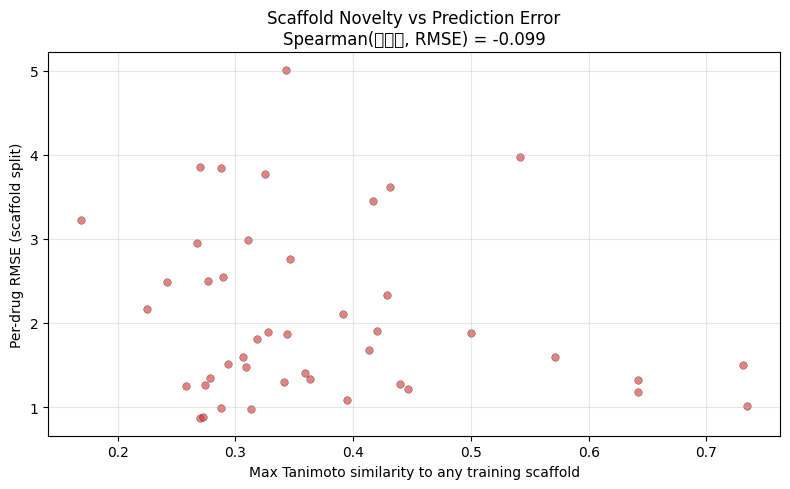

✅ OOD_scaffold_novelty_vs_error.png

按最近 scaffold 相似度分组:
         count   mean  median
sim_bin                      
<0.3        15  2.112   2.161
0.3-0.5     23  2.120   1.871
0.5-0.7      4  2.020   1.463
>0.7         2  1.253   1.253


/tmp/ipykernel_931/1873418491.py:130: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(plot_df.groupby('sim_bin')['rmse'].agg(['count', 'mean', 'median']).round(3))


In [11]:
# ============================================================
# Cell 6: Scaffold 新颖度 vs 预测误差
# 对每个测试药物: x = 与训练集最近 scaffold 的 Tanimoto 相似度
#                y = 该药物的预测 RMSE
# ============================================================


# ---------- 1. 药物 SMILES 反查表 ----------
drug_raw = pd.read_csv('drug_smiles.csv')
name_col   = 'drug_name'
smiles_col = 'canonical_smiles'
drug_lookup = (drug_raw[[name_col, smiles_col]]
               .dropna()
               .drop_duplicates(name_col))
drug_lookup.columns = ['DRUG_NAME', 'SMILES']

print(f"[drug_lookup] 总药物数: {len(drug_lookup)}")
print(f"[drug_lookup] SMILES 非空: {drug_lookup['SMILES'].notna().sum()}")

# ---------- 2. scaffold 指纹函数（★ 修复核心：类型检查） ----------
morgan = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def scaffold_fp(smiles):
    # ★ 修复点：pandas NaN / float / None 全部挡在这里
    if not isinstance(smiles, str):
        return None
    smiles = smiles.strip()
    if smiles == '':
        return None
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    try:
        scaf_smi = MurckoScaffold.MurckoScaffoldSmiles(mol=mol)
    except Exception:
        scaf_smi = ''
    # 空 scaffold（如单原子、链状）：退回用母体分子
    scaf_mol = Chem.MolFromSmiles(scaf_smi) if scaf_smi else mol
    if scaf_mol is None:
        return None
    return morgan.GetFingerprint(scaf_mol)

# ---------- 3. 只对 scaffold split 做 ----------
split = 'scaffold'
p = preds_store[split]
test_df = p['test_df'].copy()
trainval_df = pd.read_pickle('train_scaffold.pkl')

# ---------- 4. 训练集药物 scaffold 指纹 ----------
tr_drugs = (trainval_df[['DRUG_NAME']].drop_duplicates('DRUG_NAME')
            .merge(drug_lookup, on='DRUG_NAME', how='left'))
n_before = len(tr_drugs)
n_smiles_ok = tr_drugs['SMILES'].notna().sum()
print(f"\n[train] 药物数={n_before}, 有 SMILES 的={n_smiles_ok} "
      f"({n_smiles_ok / n_before:.1%})")

tr_drugs['fp'] = tr_drugs['SMILES'].map(scaffold_fp)
tr_drugs = tr_drugs[tr_drugs['fp'].notna()].copy()
print(f"[train] 可算 scaffold 的药物数: {len(tr_drugs)}")

if len(tr_drugs) == 0:
    raise RuntimeError(
        "训练集没有任何有效 scaffold —— drug_smiles.csv 与 GDSC DRUG_NAME 映射失败。\n"
        "检查 drug_smiles.csv 的 drug_name 是否与 GDSC DRUG_NAME 完全一致。")

# ---------- 5. 测试集药物 scaffold 指纹 ----------
te_drugs = (test_df[['DRUG_NAME']].drop_duplicates('DRUG_NAME')
            .merge(drug_lookup, on='DRUG_NAME', how='left'))
n_test_before = len(te_drugs)
n_test_smiles_ok = te_drugs['SMILES'].notna().sum()
print(f"\n[test] 药物数={n_test_before}, 有 SMILES 的={n_test_smiles_ok} "
      f"({n_test_smiles_ok / n_test_before:.1%})")

te_drugs['fp'] = te_drugs['SMILES'].map(scaffold_fp)
te_drugs = te_drugs[te_drugs['fp'].notna()].copy()
print(f"[test] 可算 scaffold 的药物数: {len(te_drugs)}")

if len(te_drugs) == 0:
    raise RuntimeError("测试集没有任何有效 scaffold。")

# ---------- 6. 每个测试药物 → 训练集最近 scaffold 的 Tanimoto ----------
def max_sim(fp, ref_fps):
    if fp is None or len(ref_fps) == 0:
        return np.nan
    sims = DataStructs.BulkTanimotoSimilarity(fp, ref_fps)
    return float(np.max(sims)) if len(sims) > 0 else np.nan

ref_fps = tr_drugs['fp'].tolist()
te_drugs['max_sim'] = te_drugs['fp'].map(lambda x: max_sim(x, ref_fps))

# ---------- 7. 每个测试药物的 RMSE ----------
df = test_df.copy()
df['pred'] = p['preds']
df['true'] = p['trues']
df['err']  = df['pred'] - df['true']
drug_rmse = (df.groupby('DRUG_NAME')
             .apply(lambda g: np.sqrt(np.mean(g['err']**2)))
             .rename('rmse')
             .reset_index())

plot_df = (te_drugs.merge(drug_rmse, on='DRUG_NAME', how='inner')
           .dropna(subset=['max_sim', 'rmse']))

print(f"\n[analysis] 可分析药物数: {len(plot_df)}")

print(f"  max_sim 范围: [{plot_df['max_sim'].min():.3f}, {plot_df['max_sim'].max():.3f}]")
print(f"  RMSE 范围:    [{plot_df['rmse'].min():.3f}, {plot_df['rmse'].max():.3f}]")
corr = plot_df[['max_sim', 'rmse']].corr(method='spearman').iloc[0, 1]
print(f"  Spearman(max_sim, rmse) = {corr:.4f}")

# ---------- 8. 画图 ----------
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(plot_df['max_sim'], plot_df['rmse'],
           s=30, alpha=0.6, color='#d32f2f', edgecolor='k', linewidth=0.3)
ax.set_xlabel('Max Tanimoto similarity to any training scaffold')
ax.set_ylabel('Per-drug RMSE (scaffold split)')
ax.set_title(f'Scaffold Novelty vs Prediction Error\n'
             f'Spearman(相似度, RMSE) = {corr:.3f}')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('OOD_scaffold_novelty_vs_error.png', dpi=150)
plt.show()
print("✅ OOD_scaffold_novelty_vs_error.png")

# ---------- 9. 按相似度分组统计 ----------
plot_df['sim_bin'] = pd.cut(plot_df['max_sim'],
                            bins=[0, 0.3, 0.5, 0.7, 1.0],
                            labels=['<0.3', '0.3-0.5', '0.5-0.7', '>0.7'])
print("\n按最近 scaffold 相似度分组:")
print(plot_df.groupby('sim_bin')['rmse'].agg(['count', 'mean', 'median']).round(3))

[scaffold] 可画 Spearman 的药物数: 46
count    46.000
mean      0.514
std       0.168
min       0.100
25%       0.426
50%       0.531
75%       0.656
max       0.767
Name: spearman, dtype: float64


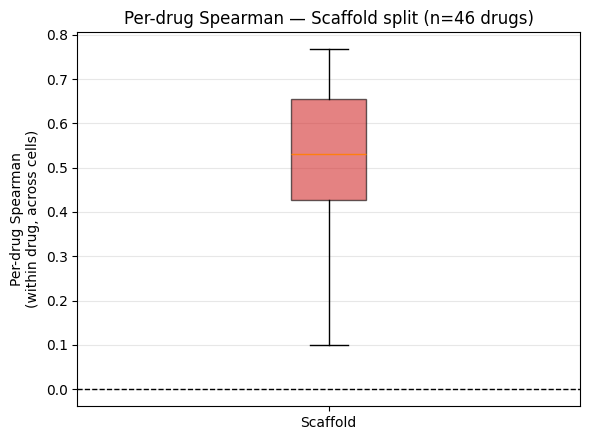

✅ OOD_per_drug_spearman_scaffold.png


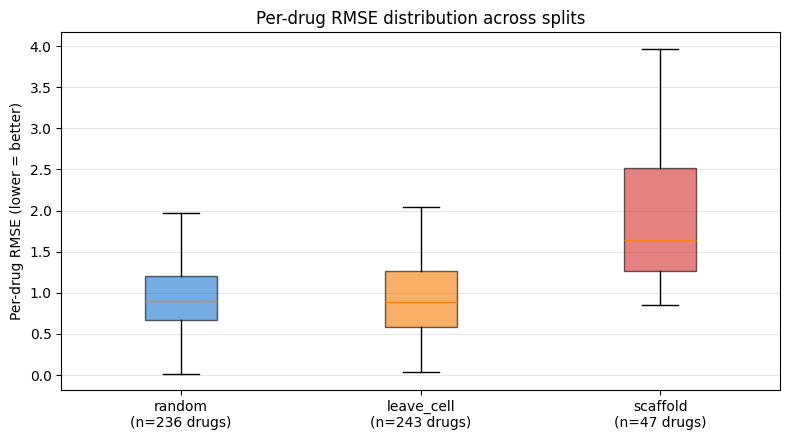

✅ OOD_per_drug_rmse_box.png

Per-drug RMSE 汇总:
  random      : n=236 | median=0.896 | IQR=[0.669, 1.198]
  leave_cell  : n=243 | median=0.885 | IQR=[0.589, 1.265]
  scaffold    : n= 47 | median=1.644 | IQR=[1.269, 2.523]


In [12]:
# ============================================================
# Cell 7:
#   (a) per-drug Spearman 箱型图 —— 只画 scaffold
#   (b) per-drug RMSE 分布 —— 三个 split 都画（RMSE 不需要样本多）
# ============================================================

# ---------- (a) Spearman 箱型图（只对 scaffold 画） ----------
sp_df_scaf = []
pstats = per_drug_stats('scaffold', min_n=10)
for _, row in pstats.iterrows():
    if not np.isnan(row['spearman']):
        sp_df_scaf.append({'DRUG_NAME': row['DRUG_NAME'],
                           'spearman': row['spearman'],
                           'rmse':     row['rmse']})
sp_df_scaf = pd.DataFrame(sp_df_scaf)
print(f"[scaffold] 可画 Spearman 的药物数: {len(sp_df_scaf)}")
print(sp_df_scaf['spearman'].describe().round(3))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.boxplot([sp_df_scaf['spearman'].values],
           tick_labels=['Scaffold'],
           patch_artist=True,
           boxprops=dict(facecolor='#d32f2f', alpha=0.6))
ax.axhline(0, color='k', linestyle='--', linewidth=1)
ax.set_ylabel('Per-drug Spearman\n(within drug, across cells)')
ax.set_title(f'Per-drug Spearman — Scaffold split (n={len(sp_df_scaf)} drugs)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('OOD_per_drug_spearman_scaffold.png', dpi=150)
plt.show()
print("✅ OOD_per_drug_spearman_scaffold.png")

# ---------- (b) per-drug RMSE 分布（三 split 都画） ----------
rmse_data, labels, counts = [], [], []
for split in SPLIT_NAMES:
    # RMSE 只需要 n>=1 就能算，min_n=1 即可
    pstats = per_drug_stats(split, min_n=1)
    if len(pstats) == 0:
        continue
    rmse_data.append(pstats['rmse'].values)
    labels.append(f"{split}\n(n={len(pstats)} drugs)")
    counts.append(len(pstats))

fig, ax = plt.subplots(figsize=(8, 4.5))
bp = ax.boxplot(rmse_data, tick_labels=labels, patch_artist=True,
                showfliers=False)   # 不画 outlier，否则 scaffold 里极值撑爆
colors = ['#1976d2', '#f57c00', '#d32f2f']
for patch, color in zip(bp['boxes'], colors[:len(rmse_data)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

ax.set_ylabel('Per-drug RMSE (lower = better)')
ax.set_title('Per-drug RMSE distribution across splits')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('OOD_per_drug_rmse_box.png', dpi=150)
plt.show()
print("✅ OOD_per_drug_rmse_box.png")

# 汇总表
print("\nPer-drug RMSE 汇总:")
for split in SPLIT_NAMES:
    pstats = per_drug_stats(split, min_n=1)
    if len(pstats) == 0:
        print(f"  {split:<12}: 无数据")
        continue
    print(f"  {split:<12}: n={len(pstats):3d} | "
          f"median={pstats['rmse'].median():.3f} | "
          f"IQR=[{pstats['rmse'].quantile(0.25):.3f}, "
          f"{pstats['rmse'].quantile(0.75):.3f}]")

Prediction Variance Analysis (shrinkage to mean)
random       | pred_std=2.267 | true_std=2.631 | ratio=0.862
leave_cell   | pred_std=2.209 | true_std=2.592 | ratio=0.852
scaffold     | pred_std=1.630 | true_std=2.459 | ratio=0.663


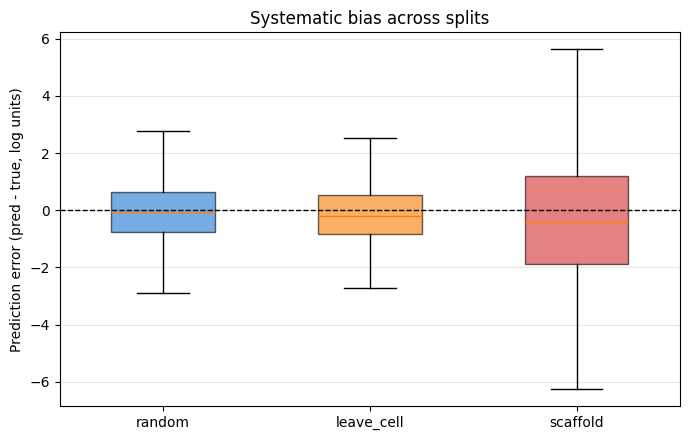


Systematic bias (mean of pred - true):
  random       | mean_err=-0.055 | median=-0.067 | |mean_err|>2 的比例 = 6.0%
  leave_cell   | mean_err=-0.147 | median=-0.187 | |mean_err|>2 的比例 = 7.0%
  scaffold     | mean_err=-0.316 | median=-0.425 | |mean_err|>2 的比例 = 36.8%


In [13]:
# ============================================================
# Cell 8: 三 split 的 prediction shrinkage + mean_err 分布
# 量化 "scaffold 是系统性偏移" 的核心结论
# ============================================================

print("=" * 70)
print("Prediction Variance Analysis (shrinkage to mean)")
print("=" * 70)

for split in SPLIT_NAMES:
    p = preds_store[split]
    pred_std = float(np.std(p['preds']))
    true_std = float(np.std(p['trues']))
    ratio = pred_std / true_std
    print(f"{split:<12s} | pred_std={pred_std:.3f} | "
          f"true_std={true_std:.3f} | ratio={ratio:.3f}")

# mean_err 分布箱型图
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = ['#1976d2', '#f57c00', '#d32f2f']
for split, color in zip(SPLIT_NAMES, colors):
    p = preds_store[split]
    err = p['preds'] - p['trues']
    ax.boxplot([err], positions=[SPLIT_NAMES.index(split)],
               widths=0.5, patch_artist=True, showfliers=False,
               boxprops=dict(facecolor=color, alpha=0.6))
ax.axhline(0, color='k', linestyle='--', linewidth=1)
ax.set_xticks(range(len(SPLIT_NAMES)))
ax.set_xticklabels(SPLIT_NAMES)
ax.set_ylabel('Prediction error (pred - true, log units)')
ax.set_title('Systematic bias across splits')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('OOD_prediction_bias_box.png', dpi=150)
plt.show()

# 每个 split 的 mean_err 统计
print("\nSystematic bias (mean of pred - true):")
for split in SPLIT_NAMES:
    p = preds_store[split]
    err = p['preds'] - p['trues']
    print(f"  {split:<12s} | mean_err={err.mean():+.3f} | "
          f"median={np.median(err):+.3f} | "
          f"|mean_err|>2 的比例 = {(np.abs(err) > 2).mean():.1%}")

In [14]:
# ============================================================
# Cell 9: Temozolomide 及 GBM 关键药物的具体预测值
# ============================================================
GBM_DRUGS = ['Temozolomide', 'TMZ', 'Lomustine', 'Carmustine',
             'Irinotecan', 'Etoposide']

for split in SPLIT_NAMES:
    p = preds_store[split]
    df = p['test_df'].copy()
    df['pred'] = p['preds']
    df['true'] = p['trues']
    df['err'] = df['pred'] - df['true']

    print(f"\n{'='*70}\n[{split}] GBM-related drugs")
    for drug_kw in GBM_DRUGS:
        sub = df[df['DRUG_NAME'].str.contains(drug_kw, case=False, na=False)]
        if len(sub) == 0:
            continue
        print(f"\n  {drug_kw} (n={len(sub)}):")
        print(f"    true:  mean={sub['true'].mean():+.2f}, "
              f"std={sub['true'].std():.2f}")
        print(f"    pred:  mean={sub['pred'].mean():+.2f}, "
              f"std={sub['pred'].std():.2f}")
        print(f"    mean_err = {sub['err'].mean():+.2f}, "
              f"RMSE = {np.sqrt((sub['err']**2).mean()):.2f}")


[random] GBM-related drugs

  Temozolomide (n=4):
    true:  mean=+6.50, std=0.69
    pred:  mean=+6.17, std=0.17
    mean_err = -0.33, RMSE = 0.67

  Irinotecan (n=6):
    true:  mean=+3.44, std=1.49
    pred:  mean=+2.69, std=0.43
    mean_err = -0.75, RMSE = 1.51

[leave_cell] GBM-related drugs

  Temozolomide (n=4):
    true:  mean=+6.78, std=0.85
    pred:  mean=+6.13, std=0.24
    mean_err = -0.65, RMSE = 1.08

  Irinotecan (n=4):
    true:  mean=+3.74, std=1.23
    pred:  mean=+2.53, std=0.17
    mean_err = -1.21, RMSE = 1.61

[scaffold] GBM-related drugs

  Temozolomide (n=24):
    true:  mean=+6.45, std=1.09
    pred:  mean=+3.32, std=0.47
    mean_err = -3.13, RMSE = 3.22

  Irinotecan (n=24):
    true:  mean=+2.76, std=1.50
    pred:  mean=-1.01, std=0.55
    mean_err = -3.78, RMSE = 3.97


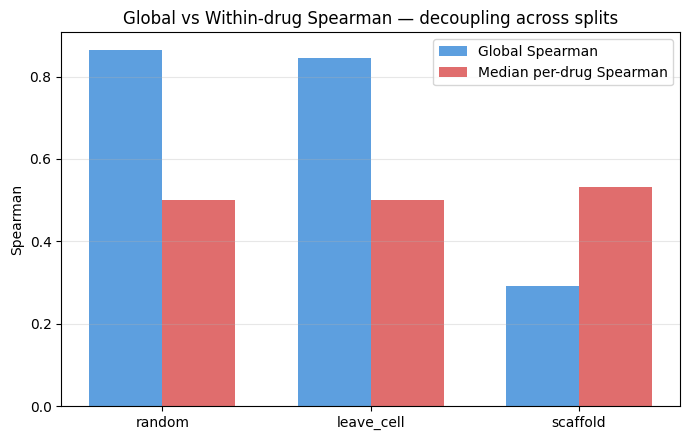

In [15]:
# ============================================================
# Cell 10: Global Spearman vs Per-drug Spearman 脱钩
# 三 split 上 per-drug Spearman 分布几乎一样，但 global 差很大
# ============================================================
fig, ax = plt.subplots(figsize=(7, 4.5))
global_sp = []
median_wc = []
for split in SPLIT_NAMES:
    pstats = per_drug_stats(split, min_n=10 if split == 'scaffold' else 3)
    global_sp.append(preds_store[split]['spearman'])
    median_wc.append(pstats['spearman'].median())

x = np.arange(len(SPLIT_NAMES))
width = 0.35
ax.bar(x - width/2, global_sp, width, label='Global Spearman',
       color='#1976d2', alpha=0.7)
ax.bar(x + width/2, median_wc, width, label='Median per-drug Spearman',
       color='#d32f2f', alpha=0.7)
ax.set_xticks(x)
ax.set_xticklabels(SPLIT_NAMES)
ax.set_ylabel('Spearman')
ax.set_title('Global vs Within-drug Spearman — decoupling across splits')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('OOD_global_vs_within_drug_spearman.png', dpi=150)
plt.show()